# SVM for Satellite Scene Classification: Preprocessing

**Dataset:** 45 scene classes, 700 images per class, 256×256 RGB.<br>
Split used here: 490 / 105 / 105 images per class (train / validation / test) = 70 / 15 / 15 %.<br>

**Rules:**
- Every fitted step (label encoder, scaler, PCA) is fitted on **train only**.
- All preprocessing choices (features, size, scaling, weights, PCA) are made on **validation**.
- The **test set is used once**, at the end.

**Goal:** build and justify the preprocessing, then hand ready-to-use features to the people working on the SVM.<br>
**Output (2 files):**
- `preprocessed_data.npz`: final features (after scaling, weighting, PCA) + labels, for the SVM team.
- `svm_baseline.joblib`: fitted preprocessing, baseline SVM, metrics, ablations, predictions.

# Imports and Paths

In [1]:
import gc
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image
from skimage.feature import hog
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.svm import SVC


## Settings
All choices live here - change them in **one place only**. Every later cell reads these values.

In [2]:
SEED = 42
SIZE = 128
HOG_ON_COLOR = False
HOG_PARAMS = {'orientations': 9, 'pixels_per_cell': (16, 16),
            'cells_per_block': (2, 2), 'block_norm': 'L2-Hys'}
N_BINS = 16
N_COLOR = 3 * N_BINS
PCA_VAR = 0.95

SUBSET_FRAC = 0.3                            # share of train used in the ablations (speed)
BASELINE_SVM = {'C': 10, 'gamma': 'scale'}   # untuned SVM, only used to check the preprocessing

DATA_DIR = Path('data')                      # contains one folder per class
FEAT_DIR = Path('features')                  # feature cache (not a result)
RESULTS_FILE = Path('svm_baseline.joblib')   # pipeline + baseline SVM + metrics
DATA_FILE = Path('preprocessed_data.npz')    # final features for the SVM team


def hog_length(size):
    '''Expected HOG vector length, computed from the settings.'''
    ppc = HOG_PARAMS['pixels_per_cell'][0]
    cpb = HOG_PARAMS['cells_per_block'][0]
    return (size // ppc - cpb + 1) ** 2 * cpb ** 2 * HOG_PARAMS['orientations']

# Load the splits

Each parquet file has two columns: `image_path` and `label`.<br>
`train.parquet`, `validation.parquet` and `test.parquet` are the three splits.

In [3]:
train_df = pd.read_parquet('train.parquet')
val_df = pd.read_parquet('validation.parquet')
test_df = pd.read_parquet('test.parquet')

print(f'Train: {len(train_df)} | Validation: {len(val_df)} | Test: {len(test_df)}')
train_df.head()

Train: 22050 | Validation: 4725 | Test: 4725


,image_path,label
0,images/roundabout/roundabout_23313.jpg,roundabout
1,images/baseball_diamond/baseball_diamond_1666.jpg,baseball_diamond
2,images/tennis_court/tennis_court_29007.jpg,tennis_court
3,images/meadow/meadow_15529.jpg,meadow
4,images/commercial_area/commercial_area_7197.jpg,commercial_area


# Build real-life paths

The parquet paths start with `images/`, but our folder is `data/`. We fix this and check that every file exists.

In [4]:
def to_real_path(rel):
    return DATA_DIR / Path(rel).relative_to('images')

for df in (train_df, val_df, test_df):
    df['path'] = df['image_path'].map(to_real_path)

missing = sum(not p.exists() for df in (train_df, val_df, test_df) for p in df['path'])
print('Missing files:', missing)

CLASS_NAMES = sorted(train_df['label'].unique())
print('Number of classes:', len(CLASS_NAMES))

Missing files: 0
Number of classes: 45


# Data Inspection

## Class Imbalance
If min = max for every split, the data is perfectly balanced (no need for class weights or resampling).

In [5]:
counts = pd.DataFrame({
    'train': train_df['label'].value_counts(),
    'val': val_df['label'].value_counts(),
    'test': test_df['label'].value_counts(),
})
print(counts.agg(['min', 'max']))

     train  val  test
min    490  105   105
max    490  105   105


## One sample per class
A quick look at what each class looks like.

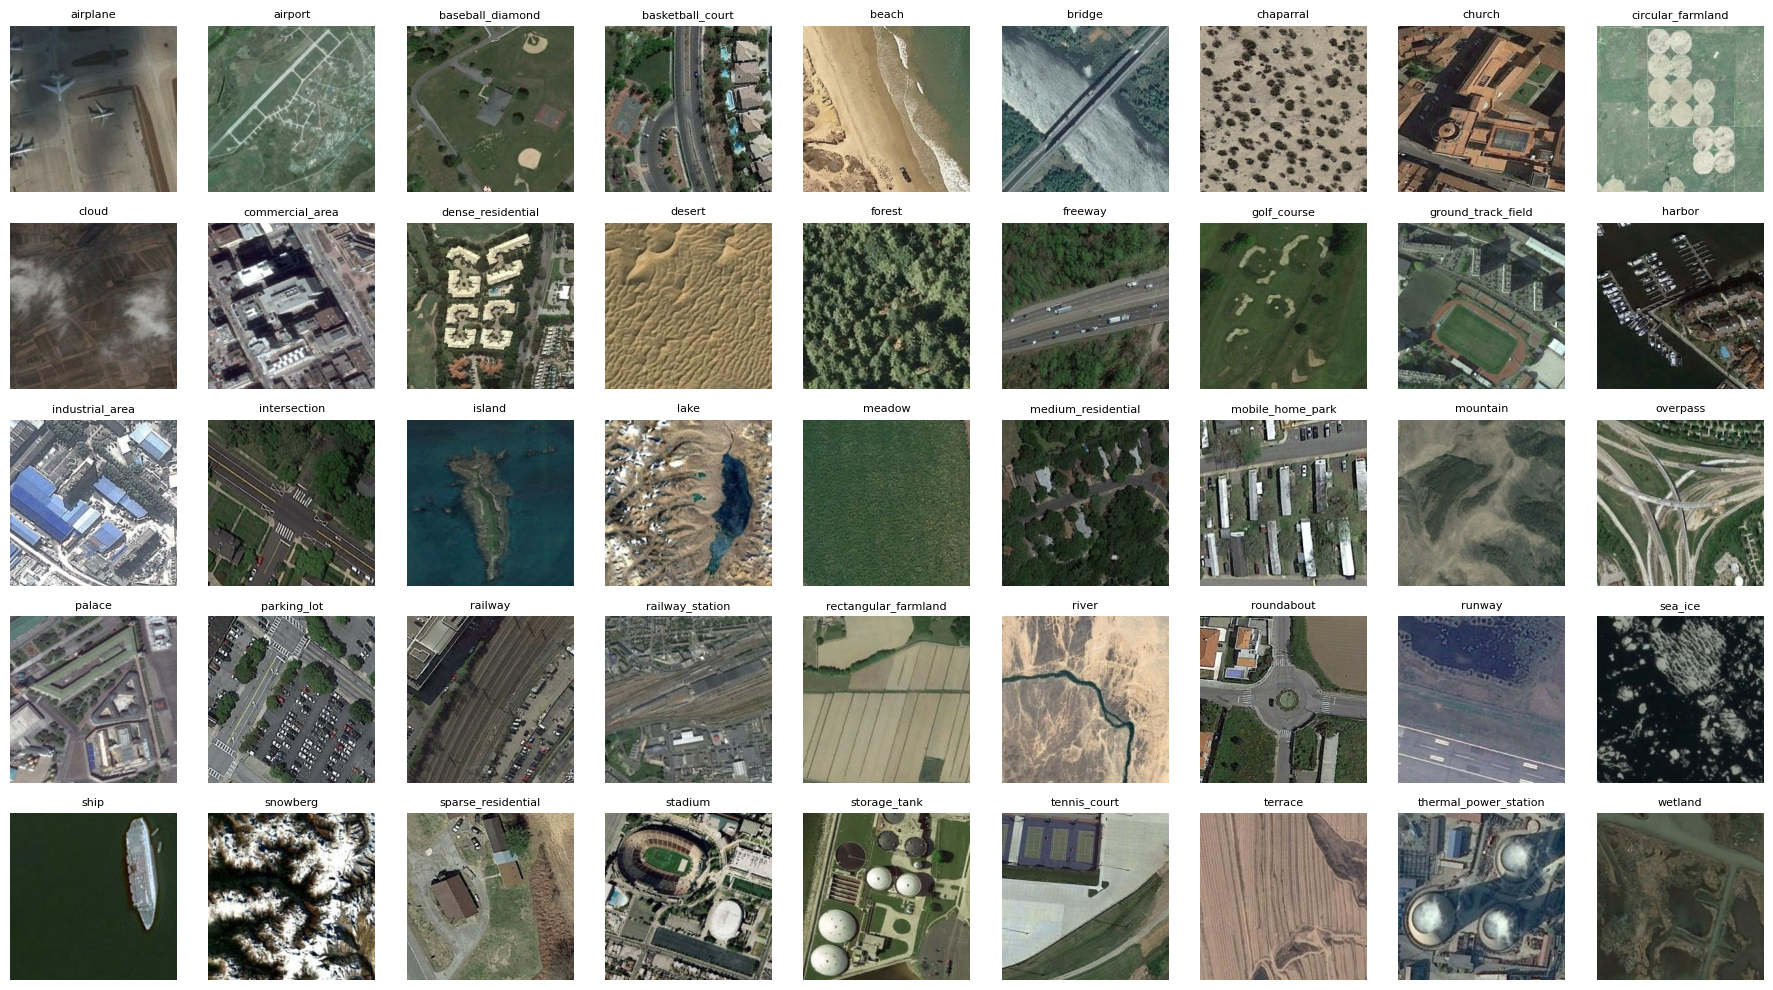

In [6]:
samples = train_df.groupby('label').sample(1, random_state=SEED)

fig, axes = plt.subplots(5, 9, figsize=(18, 10))
for ax, (_, row) in zip(axes.flat, samples.iterrows()):
    ax.imshow(Image.open(row['path']))
    ax.set_title(row['label'], fontsize=8)
    ax.axis('off')
plt.tight_layout()
plt.show()

## Variation inside one class
Same class, very different images (angle, season, lighting, density). 

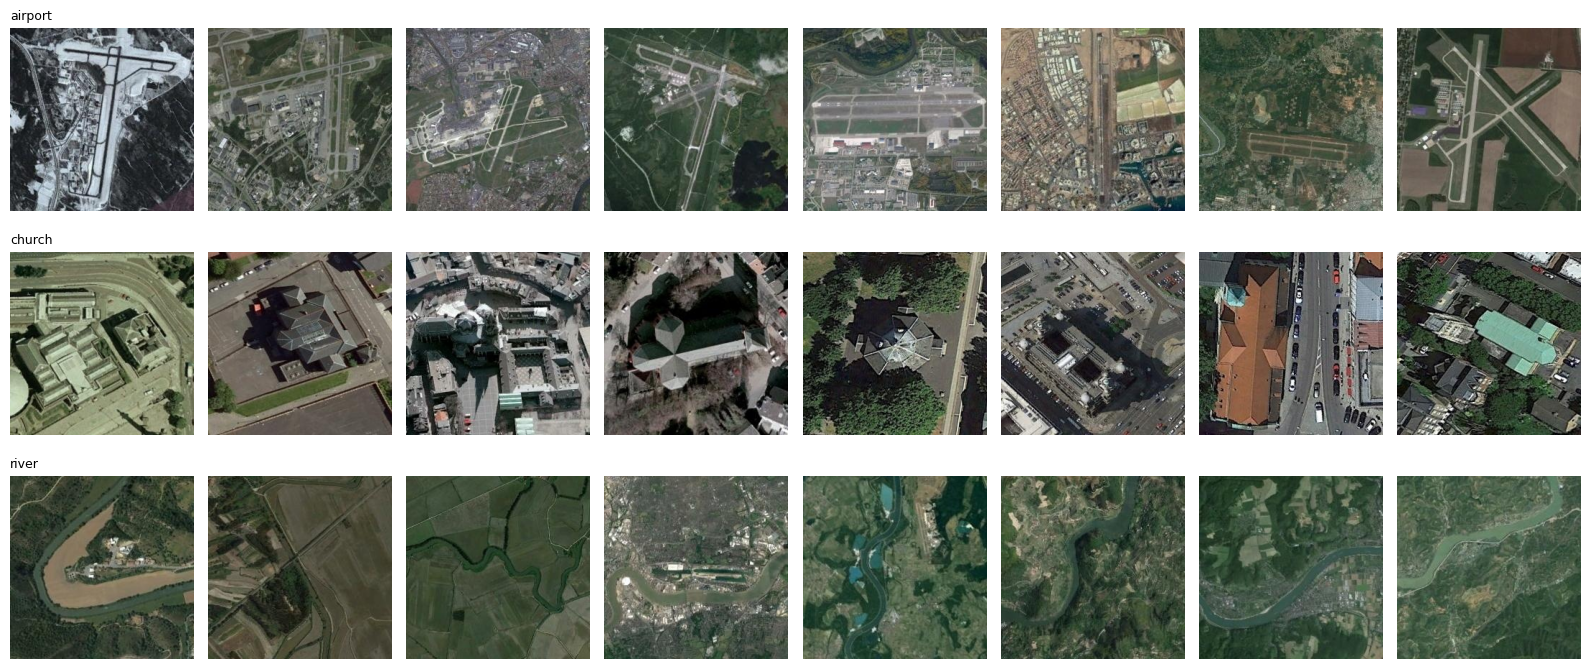

In [7]:
fig, axes = plt.subplots(3, 8, figsize=(16, 7))
for r, cls in enumerate(['airport', 'church', 'river']):
    imgs = train_df[train_df['label'] == cls].sample(8, random_state=1)
    for ax, p in zip(axes[r], imgs['path']):
        ax.imshow(Image.open(p)); ax.axis('off')
    axes[r][0].set_title(cls, fontsize=9, loc='left')
plt.tight_layout(); plt.show()

## Image size and color mode
Checked on a random sample of 500 training images. Tells us whether we need to fix sizes or convert to RGB.

In [8]:
def get_info(p):
    with Image.open(p) as im:
        return im.size, im.mode

subset = train_df.sample(500, random_state=0)
print(pd.Series([get_info(p) for p in subset['path']]).value_counts())

((256, 256), RGB)    500
Name: count, dtype: int64


## Pixel intensity per color channel
Shows the color distribution (100 images). 

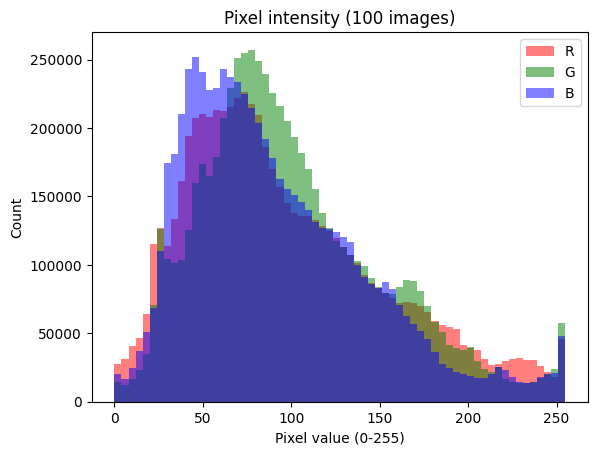

In [9]:
pixels = np.concatenate([
    np.asarray(Image.open(p).convert('RGB')).reshape(-1, 3)
    for p in subset['path'].iloc[:100]
])

for i, c in enumerate('rgb'):
    plt.hist(pixels[:, i], bins=64, alpha=0.5, color=c, label=c.upper())
plt.title('Pixel intensity (100 images)')
plt.xlabel('Pixel value (0-255)')
plt.ylabel('Count')
plt.legend()
plt.show()

## Summary
- 45 classes, split 490 / 105 / 105 images per class (train / validation / test) → perfectly balanced.
- In the 500-image sample, all images are 256×256 RGB → no color-mode fix needed; resizing is only our choice.
- Chance level is 1/45 ≈ 2.2 %, so any accuracy far above this means the features carry real information.
- The data is clean and balanced → plain accuracy and macro-F1 are valid metrics.

# SVM Preprocessing

Pipeline: `image → resize 128×128 → HOG + color histogram → StandardScaler → block weighting → PCA → SVM (RBF)`

| Step | Why |
|---|---|
| Resize | smaller input = much faster HOG |
| HOG (gray) | edges and shapes (roads, buildings, runways) |
| Color histogram | color (water, vegetation, desert) |
| StandardScaler | RBF kernel is distance-based; features with large scale would dominate |
| Block weighting | HOG has 1764 features, color only 48; without weights color is drowned out |
| PCA | removes redundancy and noise, faster SVM |
| SVM (RBF) | strong classical classifier for medium-size feature vectors |

All fitted steps (encoder, scaler, PCA) use **train only**, then are applied to val and test.

## Label encoding
The SVM needs numeric labels, so we convert class names to numbers (alphabetical order, stored in `le.classes_`).

In [10]:
# Fit on train only, then apply to all splits
le = LabelEncoder().fit(train_df['label'])
y_train = le.transform(train_df['label'])
y_val = le.transform(val_df['label'])
y_test = le.transform(test_df['label'])

## Feature extraction function
The SVM cannot learn features by itself, so we create them manually:
- **Resize to 128×128:** enough detail for HOG and much faster than 256.
- **HOG (on grayscale):** 9 orientations, 16×16-pixel cells, 2×2-cell blocks → 7×7 blocks × 36 = **1764** numbers.
- **Color histogram:** 16 bins per channel × 3 channels = **48** numbers, normalized to sum 1.

Each image becomes one vector of 1764 + 48 = **1812** numbers.

In [11]:
def extract_features(paths, size=SIZE, hog_on_color=HOG_ON_COLOR):
    features = []
    for p in paths:
        img = Image.open(p).convert('RGB').resize((size, size))
        rgb = np.asarray(img)
        hog_in = rgb if hog_on_color else np.asarray(img.convert('L'))
        hog_vec = hog(hog_in, channel_axis=-1 if hog_on_color else None, **HOG_PARAMS)

        hist = np.concatenate([
            np.histogram(rgb[..., c], bins=N_BINS, range=(0, 256))[0] for c in range(3)
        ]).astype(np.float32)
        hist /= hist.sum()
        features.append(np.concatenate([hog_vec, hist]))
    return np.array(features, dtype=np.float32)

## Shared helpers for the ablations

In [12]:
def block_weights(n_total):
    w = np.ones(n_total)
    w[:n_total - N_COLOR] = 1 / np.sqrt(n_total - N_COLOR)
    w[n_total - N_COLOR:] = 1 / np.sqrt(N_COLOR)
    return w

In [13]:
idx = train_test_split(np.arange(len(y_train)), train_size=SUBSET_FRAC,
                    stratify=y_train, random_state=SEED)[0]

def evaluate_cfg(Xtr, ytr, Xva, yva, scale=True, weight=True, use_pca=True, C=10):
    if scale:
        s = StandardScaler().fit(Xtr)
        Xtr, Xva = s.transform(Xtr), s.transform(Xva)
    if weight:
        w = block_weights(Xtr.shape[1])
        Xtr, Xva = Xtr * w, Xva * w
    if use_pca:
        p = PCA(n_components=PCA_VAR, svd_solver='full').fit(Xtr)
        Xtr, Xva = p.transform(Xtr), p.transform(Xva)
    svm = SVC(kernel='rbf', C=C, gamma='scale').fit(Xtr, ytr)
    return accuracy_score(yva, svm.predict(Xva))

## Ablation 1: image size and HOG input
Compares size (64 / 128 / 256) and HOG on gray vs color.
Uses 30 % of train and 1500 random validation images, so the numbers are **not comparable** with Ablation 2.

In [14]:
val_idx = np.random.RandomState(0).choice(len(val_df), 1500, replace=False)
train_paths = train_df['path'].iloc[idx]
val_paths = val_df['path'].iloc[val_idx]

size_results = {}
for size in [64, 128, 256]:
    for on_color in [False, True]:
        Xtr = extract_features(train_paths, size, on_color)
        Xva = extract_features(val_paths, size, on_color)
        color_tag = "color" if on_color else "gray"
        name = f"size={size}, HOG on {color_tag}"
        size_results[name] = evaluate_cfg(Xtr, y_train[idx], Xva, y_val[val_idx])
        print(name, '->', round(size_results[name], 4))

size_table = pd.Series(size_results, name='val_acc').sort_values(ascending=False).round(4)
size_table

size=64, HOG on gray -> 0.4867
size=64, HOG on color -> 0.49
size=128, HOG on gray -> 0.5027
size=128, HOG on color -> 0.5053
size=256, HOG on gray -> 0.5067
size=256, HOG on color -> 0.5027


size=256, HOG on gray     0.5067
size=128, HOG on color    0.5053
size=128, HOG on gray     0.5027
size=256, HOG on color    0.5027
size=64, HOG on color     0.4900
size=64, HOG on gray      0.4867
Name: val_acc, dtype: float64

**Decision: 128 + HOG on gray.**
- 128 vs 256 and gray vs color differ by ≤ 0.4 % (about 6 images), which is noise (1 standard error ≈ 1.3 % on 1500 images).
- Size 64 is about 1.5-2 points lower: a small, borderline drop.
- 128 gray is the cheapest option with the same accuracy.

**Limitation:** `pixels_per_cell` is fixed at 16, so a bigger image also gives a longer HOG vector (324 / 1764 / 8100 features for 64 / 128 / 256). Size and HOG grid are therefore mixed in this comparison.

## Extract features for all splits
Extraction is slow (a few minutes), so the result is cached in `features/`.
The cache file name contains **all** feature settings (size, HOG input, HOG parameters, bins), so changing a setting can never load stale features.
The cache is not a result; it can be deleted at any time.

In [15]:
FEAT_DIR.mkdir(exist_ok=True)

def cache_tag(size, on_color):
    ppc = HOG_PARAMS['pixels_per_cell'][0]
    cpb = HOG_PARAMS['cells_per_block'][0]
    ori = HOG_PARAMS['orientations']
    color_tag = "color" if on_color else "gray"
    return f"s{size}_{color_tag}_ppc{ppc}_cpb{cpb}_o{ori}_b{N_BINS}"

TAG = cache_tag(SIZE, HOG_ON_COLOR)

def get_features(name, paths):
    file = FEAT_DIR / f'{name}_{TAG}.npy'
    if file.exists():
        X = np.load(file)
        if len(X) == len(paths):          # guard against a stale cache
            return X
    X = extract_features(paths, SIZE, HOG_ON_COLOR)
    np.save(file, X)
    return X

X_train = get_features('train', train_df['path'])
X_val   = get_features('val',   val_df['path'])
X_test  = get_features('test',  test_df['path'])

HOG_END = X_train.shape[1] - N_COLOR
assert X_train.shape[1] == X_val.shape[1] == X_test.shape[1]
assert HOG_END == hog_length(SIZE)
print('Feature shape:', X_train.shape, '| HOG_END:', HOG_END)

Feature shape: (22050, 1812) | HOG_END: 1764


## Ablation 2: is each preprocessing step helping?
Same SVM (RBF, C=10, gamma="scale"), only the preprocessing changes.
Each variant trains on 30 % of train and is scored on the **full validation set**. The test set is not used.

| Variant | What it tests |
|---|---|
| HOG only / Color only | does each feature block help on its own? |
| no scaling → scaling | effect of `StandardScaler` |
| scaling → scaling + weights | effect of block weighting |
| with / without PCA | effect of PCA |

Rule: a step stays only if it improves validation accuracy (or keeps it equal with a clear gain in speed or size).

In [16]:
Xt, Xv, yt, H = X_train[idx], X_val, y_train[idx], HOG_END

# name: (Xtr, Xva, scale, weight, pca)
variants = {
    'HOG only':                         (Xt[:, :H], Xv[:, :H], True,  False, True),
    'Color only':                       (Xt[:, H:], Xv[:, H:], True,  False, True),
    'HOG+Color, no scaling':            (Xt, Xv, False, False, False),
    'HOG+Color, scaling':               (Xt, Xv, True,  False, False),
    'HOG+Color, scaling + PCA':         (Xt, Xv, True,  False, True),
    'HOG+Color, weights, no PCA':       (Xt, Xv, True,  True,  False),
    'HOG+Color, weights + PCA (ours)':  (Xt, Xv, True,  True,  True),
}

results = {n: evaluate_cfg(a, yt, b, y_val, s, w, p)
        for n, (a, b, s, w, p) in variants.items()}
ablation = pd.Series(results, name='val_acc').sort_values(ascending=False).round(4)
print(ablation.to_string())      # saved later in the result file

HOG+Color, weights + PCA (ours)    0.5084
HOG+Color, weights, no PCA         0.5029
Color only                         0.4411
HOG+Color, scaling                 0.3835
HOG+Color, scaling + PCA           0.3799
HOG+Color, no scaling              0.3230
HOG only                           0.2919


### Reading Ablation 2
*(numbers from our run - re-check after re-running)*
- **Block weighting is the biggest win:** 0.3835 → 0.5029 (+12 points). Without it, the 1764 HOG features dominate the distance and color is ignored.
- **Scaling matters:** 0.3230 → 0.3835 (+6 points).
- **PCA:** +0.55 points with weights, which is within noise (1 standard error on 4725 images ≈ 0.7 points). We keep it because it cuts 1812 features to about 380 (faster SVM), not because it is more accurate.
- **Color alone (0.441) beats HOG alone (0.292):** color is very informative for these scenes; HOG with big 16-pixel cells is weak on its own.
- **Both together are best (0.508),** about +7 points over color only → the two blocks are complementary.

## Standardization and block weighting
- `StandardScaler`: every feature gets mean 0 and std 1 (needed for RBF). Fitted on **train only**.
- **Block weighting:** HOG has 1764 features and color only 48, so HOG would dominate the distance.
  We multiply each block by `1/sqrt(block size)` so both blocks have equal total weight and color is not drowned out.

In [17]:
scaler = StandardScaler().fit(X_train)            # learn mean/std from train only
weights = block_weights(X_train.shape[1])         # same function used in the ablation

def preprocess(X):
    return scaler.transform(X) * weights

X_train_s = preprocess(X_train)
X_val_s = preprocess(X_val)
X_test_s = preprocess(X_test)

## PCA (dimensionality reduction)
Keeps 95 % of the variance with far fewer features. This removes redundancy and noise and makes the SVM faster.
Fitted on **train only**.

In [18]:
pca = PCA(n_components=PCA_VAR, svd_solver='full').fit(X_train_s)   # train only
Z_train = pca.transform(X_train_s)
Z_val = pca.transform(X_val_s)
Z_test = pca.transform(X_test_s)
print('Features:', X_train.shape[1], '->', Z_train.shape[1])

Features: 1812 -> 381


In [19]:
del X_train_s, X_val_s, X_test_s, X_train, X_val, X_test
plt.close('all')
gc.collect()

125035

## Baseline SVM and test result
Preprocessing is finished. One untuned SVM (C=10, gamma="scale") is trained on the **full** train set only to check that the features work.
Validation accuracy is the reference. The test set is evaluated **once**.

**No tuning here.** An earlier 15-trial Optuna search (30 % of train) reached 0.5058 validation accuracy, which did not beat the untuned baseline on the same subset (0.5084, Ablation 2).
On the full train set the tuned model was also not better (0.6030 vs 0.6047). SVM tuning is left to the SVM owners.

In [20]:
svm = SVC(kernel='rbf', **BASELINE_SVM).fit(Z_train, y_train)
val_acc = accuracy_score(y_val, svm.predict(Z_val))
print(f'Validation accuracy: {val_acc:.4f}')

pred = svm.predict(Z_test)          # test used once
test_acc = accuracy_score(y_test, pred)
test_f1 = f1_score(y_test, pred, average='macro')
print('Test accuracy:', round(test_acc, 4))
print('Test macro F1:', round(test_f1, 4))

Validation accuracy: 0.6047
Test accuracy: 0.6184
Test macro F1: 0.6155


### Reading the result
*(numbers from our run - re-check after re-running)*
- Validation 0.605, test accuracy 0.618, macro-F1 0.616: close to each other → no sign of overfitting to the validation set.
- Using the full train set instead of 30 % raises validation accuracy from about 0.51 to about 0.60 with the same settings: more data helped far more than hyperparameters.
- This is the **baseline number** that the CNN / ViT models must beat.

## Per-class report
Shows which classes are hard for the SVM. Used for the error analysis section.

In [21]:
print(classification_report(y_test, pred, target_names=le.classes_))
report_dict = classification_report(y_test, pred, target_names=le.classes_, output_dict=True)

per_class = (pd.DataFrame(report_dict).T.loc[le.classes_, ['precision', 'recall', 'f1-score']]
             .sort_values('f1-score'))
print('Hardest 5 classes:\n', per_class.head(5).round(2))
print('Easiest 5 classes:\n', per_class.tail(5).round(2))

                       precision    recall  f1-score   support

             airplane       0.53      0.68      0.59       105
              airport       0.37      0.45      0.41       105
     baseball_diamond       0.51      0.43      0.46       105
     basketball_court       0.39      0.37      0.38       105
                beach       0.63      0.66      0.64       105
               bridge       0.77      0.66      0.71       105
            chaparral       0.94      0.98      0.96       105
               church       0.47      0.47      0.47       105
    circular_farmland       0.72      0.75      0.74       105
                cloud       0.78      0.61      0.68       105
      commercial_area       0.43      0.48      0.45       105
    dense_residential       0.54      0.69      0.60       105
               desert       0.80      0.91      0.85       105
               forest       0.78      0.95      0.85       105
              freeway       0.62      0.61      0.61  

## Most confused class pairs
Directional: `true → predicted`. Used for the error analysis section.

In [22]:
cm = confusion_matrix(y_test, pred)
cm_off = cm.copy()
np.fill_diagonal(cm_off, 0)   # ignore correct predictions

pairs = [(le.classes_[i], le.classes_[j], int(cm_off[i, j])) for i, j in zip(*np.nonzero(cm_off))]
confusions = (pd.DataFrame(pairs, columns=['true', 'predicted', 'count'])
              .sort_values('count', ascending=False).reset_index(drop=True))
confusions.head(10)

,true,predicted,count
0,freeway,railway,17
1,ship,harbor,15
2,commercial_area,church,14
3,church,commercial_area,14
4,church,palace,13
5,tennis_court,medium_residential,13
6,railway_station,airport,12
7,dense_residential,medium_residential,12
8,railway,freeway,11
9,railway_station,railway,11


**Pattern:** the top confusions are *semantically close* classes (freeway ↔ railway, ship ↔ harbor, church ↔ palace ↔ commercial_area, dense ↔ medium residential).
Handcrafted edge + color features cannot separate scenes that share the same textures and colors. This motivates deep models that learn object- and layout-level features.

## Save the outputs
- `preprocessed_data.npz`: `Z_train / Z_val / Z_test` (after scaling, weighting, PCA), the labels, and the class names. The SVM team can load it directly without re-extracting features.
- `svm_baseline.joblib`: config, metrics (val + test + per-class), both ablation tables, test predictions, top confusions, and the fitted preprocessing + baseline SVM.

Nothing else is written (the `features/` folder is only a cache).

In [23]:
np.savez_compressed(
    DATA_FILE,
    Z_train=Z_train.astype(np.float32), y_train=y_train,
    Z_val=Z_val.astype(np.float32),     y_val=y_val,
    Z_test=Z_test.astype(np.float32),   y_test=y_test,
    class_names=le.classes_.astype(str),
)
print('Saved ->', DATA_FILE, f'({DATA_FILE.stat().st_size / 1e6:.1f} MB)')

results = {
    'config': {
        'n_classes': len(le.classes_),
        'n_train': len(y_train), 'n_val': len(y_val), 'n_test': len(y_test),
        'seed': SEED, 'image_size': SIZE, 'hog_on_color': HOG_ON_COLOR,
        'hog': HOG_PARAMS, 'color_bins': N_BINS, 'pca_variance': PCA_VAR,
        'n_pca_components': int(pca.n_components_),
        'svm_params': BASELINE_SVM,
    },
    'metrics': {
        'val_acc': float(val_acc),
        'test_accuracy': float(test_acc),
        'test_macro_f1': float(test_f1),
        'per_class_report': report_dict,
    },
    'ablation_preprocessing': ablation.to_dict(),
    'ablation_size_hog': size_table.to_dict(),
    'predictions': {'y_test': y_test, 'y_pred': pred},
    'top_confusions': confusions.head(10),
    'model': {'scaler': scaler, 'pca': pca, 'svm': svm,
              'weights': weights, 'label_encoder': le},
}
joblib.dump(results, RESULTS_FILE, compress=3)
print('Saved ->', RESULTS_FILE, f'({RESULTS_FILE.stat().st_size / 1e6:.1f} MB)')

Saved -> preprocessed_data.npz (44.9 MB)
Saved -> svm_baseline.joblib (74.1 MB)


## Load and reuse
Check that both files load, and predict new images with the saved model.

In [24]:
data = np.load(DATA_FILE)
print({k: data[k].shape for k in data.files})

saved = joblib.load(RESULTS_FILE)
print(list(saved.keys()))
print('Test accuracy:', saved['metrics']['test_accuracy'])

def predict_images(paths, bundle=saved):
    m = bundle['model']
    X = extract_features(paths, SIZE, HOG_ON_COLOR)
    Z = m['pca'].transform(m['scaler'].transform(X) * m['weights'])
    return m['label_encoder'].inverse_transform(m['svm'].predict(Z))

predict_images(test_df['path'].iloc[:5])

{'Z_train': (22050, 381), 'y_train': (22050,), 'Z_val': (4725, 381), 'y_val': (4725,), 'Z_test': (4725, 381), 'y_test': (4725,), 'class_names': (45,)}
['config', 'metrics', 'ablation_preprocessing', 'ablation_size_hog', 'predictions', 'top_confusions', 'model']
Test accuracy: 0.6184126984126984


array(['meadow', 'golf_course', 'desert', 'harbor', 'snowberg'],
      dtype=object)

## Limitations and next steps
- Handcrafted features reach about 62 % test accuracy; confusions are between visually similar scene types.
- Preprocessing choices were **not searched exhaustively**. Fixed and untested: HOG cell size (16) and orientations, color-histogram bins, color space (RGB only), PCA variance (95 %), and the relative weight of the HOG and color blocks.
- Ablations used 30 % of train, so conclusions may shift slightly on the full set. Only one train/val/test split and one seed were used.
- SVM hyperparameters (C, gamma, kernel) were **not tuned** here; this is left to the SVM owners. Baseline: C=10, gamma="scale".
- The baseline SVM is trained on train only (val is not added back), to keep the comparison clean.
- Next: SVM tuning on `preprocessed_data.npz`, then CNN / transfer learning / ViT on the same splits, compared with the same metrics (accuracy, macro-F1, per-class F1, confusion pairs).